# TL;DR: TURF Analysis

**What I did:** Used MovieLens ratings to build a binary user-by-genre preference matrix, then ran exhaustive and greedy TURF analyses to identify four-genre combinations that maximize unique audience reach. I also conducted sensitivity analysis by varying the rating threshold (3.5, 4.0, 4.5 stars) and minimum number of qualifying movies (1, 2, 3, 5).

**Key finding:** Exhaustive TURF identified Action, Comedy, Drama, and Thriller as the optimal four-genre bundle, reaching 99.02% of users under the primary preference definition (at least three movies rated 4.0 stars or higher per genre). Greedy TURF found a similar bundle, replacing Comedy with Adventure, with 98.9% reach. Sensitivity analysis selected the exhaustive bundle in 11 of 12 tested scenarios, although estimated reach varied from 79.67% to 99.84% depending on the preference criteria.

**Product recommendation:** Prioritize Action, Comedy, Drama, and Thriller as a starting point for content selection or recommendation targeting to maximize potential audience coverage.

**Next steps:**
1. Validate whether rating-based preferences predict actual content engagement.
2. Run an experiment comparing the four-genre strategy against the current recommendation experience.
3. Measure click-through rate, watch starts, completion, and retention.
4. Segment results to identify differences across user cohorts and optimize for engagement, not just reach.

**Bottom line:** My TURF analysis identifies a promising high-reach genre bundle; product experimentation is needed to determine whether it improves user engagement and business outcomes.

In [3]:
import pandas as pd
import pandas as pd
import numpy as np
from itertools import combinations
import matplotlib.pyplot as plt

In [5]:
ratings = pd.read_csv("C:\\Users\\lmoin\\OneDrive\\Desktop\\Coding_Projects_2026_2027\\TURF_Analysis\\Turf_base_data_movielens\\ratings.csv")
movies = pd.read_csv("C:\\Users\\lmoin\\OneDrive\\Desktop\\Coding_Projects_2026_2027\\TURF_Analysis\\Turf_base_data_movielens\\movies.csv")

In [6]:
ratings.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [7]:
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [8]:
print("ratings:", ratings.shape, "| movies:", movies.shape)
print("unique users:", ratings["userId"].nunique())
print("unique movies rated:", ratings["movieId"].nunique())
ratings.head()

ratings: (100836, 4) | movies: (9742, 3)
unique users: 610
unique movies rated: 9724


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [9]:
ratings.info()
ratings.isna().sum()

movies.info()
movies.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB
<class 'pandas.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   movieId  9742 non-null   int64
 1   title    9742 non-null   str  
 2   genres   9742 non-null   str  
dtypes: int64(1), str(2)
memory usage: 228.5 KB


movieId    0
title      0
genres     0
dtype: int64

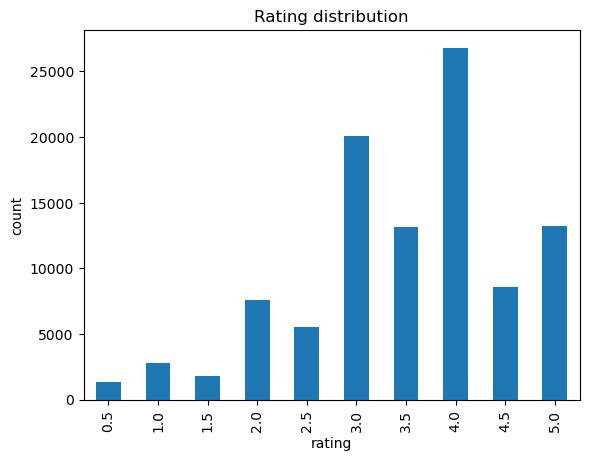

In [10]:
# Quick look at how people rate, to sanity-check the "liked" threshold
ratings["rating"].value_counts().sort_index().plot(kind="bar", title="Rating distribution")
plt.xlabel("rating"); plt.ylabel("count"); plt.show()

In [11]:
LIKE_THRESHOLD = 4.0   # a rating at or above this counts as "liked"
MIN_LIKES      = 3     # liked movies needed in a genre for that genre to "reach" a user
EXCLUDE        = {"(no genres listed)", "IMAX"}   # not real genres

In [12]:
likes = ratings[ratings["rating"] >= LIKE_THRESHOLD]

# One row per (movie, genre)
movie_genres = (
    movies.assign(genre=movies["genres"].str.split("|"))
          .explode("genre")
          .loc[lambda d: ~d["genre"].isin(EXCLUDE), ["movieId", "genre"]]
)

# Count liked movies per user per genre
user_genre_likes = (
    likes.merge(movie_genres, on="movieId")
         .groupby(["userId", "genre"]).size()
         .unstack(fill_value=0)
)

# Keep every user in the base, including those who liked nothing
all_users = np.sort(ratings["userId"].unique())
user_genre_likes = user_genre_likes.reindex(all_users, fill_value=0)

# Binary reach matrix: True = this genre reaches this user
reach_matrix = user_genre_likes >= MIN_LIKES
print("users x genres:", reach_matrix.shape)
reach_matrix.head()

users x genres: (610, 18)


genre,Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
userId,,,,,,,,,,,,,,,,,,
1,True,True,True,True,True,True,False,True,True,False,True,True,True,True,True,True,True,True
2,True,False,False,False,True,True,False,True,False,False,False,False,False,False,False,True,False,False
3,True,True,False,False,False,False,False,False,False,False,True,False,False,False,True,True,False,False
4,True,True,True,True,True,True,False,True,True,True,True,True,True,True,True,True,True,True
5,True,True,True,True,True,True,False,True,True,False,False,True,False,True,False,True,False,False


In [13]:
user_genre_likes.head() #just to see what the data looks like, not needed for the analysis

genre,Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
userId,,,,,,,,,,,,,,,,,,
1,76,74,27,37,70,39,0,64,41,1,9,20,13,24,32,43,20,6
2,7,2,0,0,5,6,2,11,0,0,0,0,2,1,2,6,1,0
3,9,4,0,0,1,0,0,1,2,0,8,0,1,0,12,6,0,0
4,13,19,4,7,58,18,1,70,13,3,4,12,14,29,5,22,5,7
5,3,3,5,7,7,7,0,14,5,0,0,4,1,3,0,5,2,1


# Let's determine Reach

Reach is defined as "How many unique users does the combination reach?"
Reach is calculated as:
\[
\text{Reach \%}=\frac{\text{Unique users reached}}{\text{Total eligible users}}\times100
\]

In [14]:
single = (reach_matrix.mean() * 100).sort_values(ascending=False).round(1)
single.to_frame("reach_%")

,reach_%
genre,
Drama,95.6
Comedy,91.8
Thriller,89.0
Action,87.5
Adventure,85.1
Crime,80.5
Romance,77.7
Sci-Fi,73.0
Fantasy,63.0


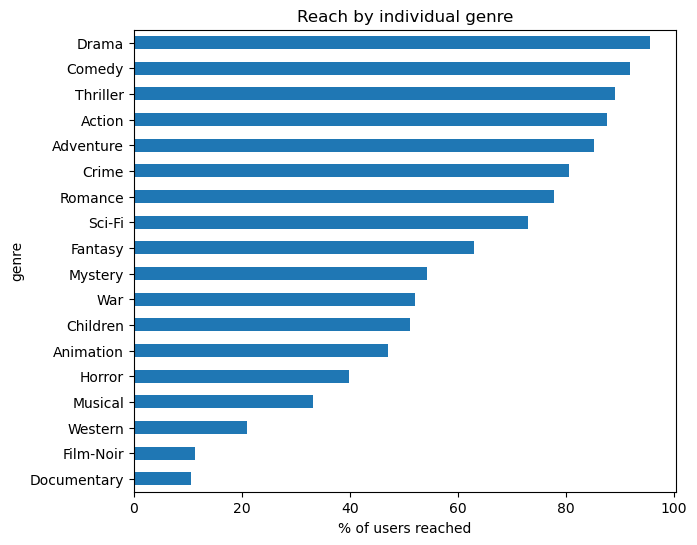

In [15]:
single.sort_values().plot(kind="barh", figsize=(7, 6), title="Reach by individual genre")
plt.xlabel("% of users reached"); plt.show()

# TURF: Exaustive Search & Global Optimum
Below we'll check every combination. There are 18 genres, and we'll go up to groups of 5. This will help us to identify the best global genre combinations and optimal size of a group/bundle (i.e. show # of genres to consumer).  

In this calculation, a user is counted as reached if they have a positive preference for at least one selected genre. Each user is counted only once. The code sorts the combinations by reach, with avg frequency as a tie breaker. 

What we're doing here simplified: 
* Testing every possible combination of the selected size.
* Calculating each combination's unique reach.
* Ranking all combinations by reach, then average frequency.
* Guaranteeing the best combination for that bundle size, assuming the input matrix and calculations are correct.

In [16]:
M = reach_matrix.to_numpy()
genres = reach_matrix.columns.to_numpy()

def turf(M, labels, k):
    """Score every k-item combination by reach, then frequency."""
    rows = []
    for combo in combinations(range(M.shape[1]), k):
        sub = M[:, list(combo)]
        hit = sub.any(axis=1)
        reach = hit.mean()
        freq = sub.sum(axis=1)[hit].mean() if hit.any() else 0.0
        rows.append((" + ".join(labels[list(combo)]), reach, freq))
    out = pd.DataFrame(rows, columns=["bundle", "reach", "avg_frequency"])
    return out.sort_values(["reach", "avg_frequency"], ascending=False).reset_index(drop=True)

MAX_SIZE = 5
results = {}
for k in range(1, MAX_SIZE + 1):
    results[k] = turf(M, genres, k)
    print(f"\nTop 5 bundles of size {k}:")
    display(results[k].head(5).style.format({"reach": "{:.1%}", "avg_frequency": "{:.2f}"}))


Top 5 bundles of size 1:


,bundle,reach,avg_frequency
0,Drama,95.6%,1.00
1,Comedy,91.8%,1.00
2,Thriller,89.0%,1.00
3,Action,87.5%,1.00
4,Adventure,85.1%,1.00



Top 5 bundles of size 2:


,bundle,reach,avg_frequency
0,Action + Drama,98.0%,1.87
1,Drama + Thriller,97.9%,1.89
2,Adventure + Drama,97.7%,1.85
3,Comedy + Drama,97.5%,1.92
4,Drama + Sci-Fi,97.4%,1.73



Top 5 bundles of size 3:


,bundle,reach,avg_frequency
0,Comedy + Drama + Thriller,98.7%,2.80
1,Action + Comedy + Drama,98.5%,2.79
2,Action + Drama + Thriller,98.5%,2.76
3,Action + Adventure + Drama,98.5%,2.72
4,Adventure + Comedy + Drama,98.4%,2.77



Top 5 bundles of size 4:


,bundle,reach,avg_frequency
0,Action + Comedy + Drama + Thriller,99.0%,3.68
1,Adventure + Comedy + Drama + Thriller,98.9%,3.66
2,Action + Adventure + Drama + Thriller,98.9%,3.61
3,Comedy + Drama + Sci-Fi + Thriller,98.9%,3.53
4,Action + Adventure + Comedy + Drama,98.7%,3.65



Top 5 bundles of size 5:


,bundle,reach,avg_frequency
0,Action + Adventure + Comedy + Drama + Thriller,99.0%,4.53
1,Action + Comedy + Crime + Drama + Thriller,99.0%,4.49
2,Action + Comedy + Drama + Romance + Thriller,99.0%,4.46
3,Action + Comedy + Drama + Sci-Fi + Thriller,99.0%,4.41
4,Action + Comedy + Drama + Fantasy + Thriller,99.0%,4.31


,size,bundle,reach,avg_frequency
0,1,Drama,95.574%,1.00
1,2,Action + Drama,98.033%,1.87
2,3,Comedy + Drama + Thriller,98.689%,2.80
3,4,Action + Comedy + Drama + Thriller,99.016%,3.68
4,5,Action + Adventure + Comedy + Drama + Thriller,99.016%,4.53


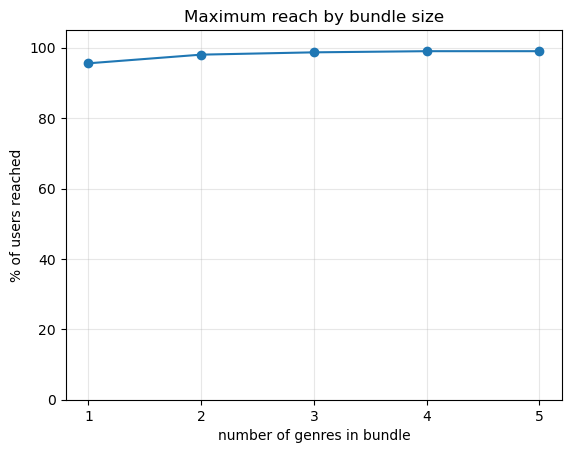

In [25]:
best = pd.DataFrame([
    {"size": k, "bundle": results[k].loc[0, "bundle"],
     "reach": results[k].loc[0, "reach"], "avg_frequency": results[k].loc[0, "avg_frequency"]}
    for k in results
])
display(best.style.format({"reach": "{:.3%}", "avg_frequency": "{:.2f}"}))

plt.plot(best["size"], best["reach"] * 100, marker="o")
plt.title("Maximum reach by bundle size")
plt.xlabel("number of genres in bundle"); plt.ylabel("% of users reached")
plt.xticks(best["size"]); plt.ylim(0, 105); plt.grid(alpha=0.3); plt.show()

In [28]:
for k in range(1, MAX_SIZE + 1):
    best = results[k].iloc[0]
    print(
        f"{k} genres: {best['bundle']} | "
        f"Reach: {best['reach']:.4%} | "
        f"Avg frequency: {best['avg_frequency']:.3f}"
    )

1 genres: Drama | Reach: 95.5738% | Avg frequency: 1.000
2 genres: Action + Drama | Reach: 98.0328% | Avg frequency: 1.868
3 genres: Comedy + Drama + Thriller | Reach: 98.6885% | Avg frequency: 2.801
4 genres: Action + Comedy + Drama + Thriller | Reach: 99.0164% | Avg frequency: 3.675
5 genres: Action + Adventure + Comedy + Drama + Thriller | Reach: 99.0164% | Avg frequency: 4.535


# Results of Initial TURF Analysis

Best results: 4 genres: Action + Comedy + Drama + Thriller | Reach: 99.0164% | Avg frequency: 3.675

This final chart shows us diminishing returns as we jump up in group size. Using rounded percentages, the fourth genre adds about 0.3 percentage points, while the fifth adds almost nothing. From this we can conclude that the ideal bundle size would be 4.

We'll consider 4 going forward, and also calculate for a bundle size of 3 assuming that there might be a business constraint in place about the number of genres we could visibly show on the screen for consumers. 

# Maximizing TURF combinations

This is another way to look at the TURF analysis, but with the goal of maximizing reach by building each combination one at a time, choosing to add whichever genre adds the most new reach at each step.  

What we're doing here simplified: 
* Starts with no genres selected.
* Picks the genre that reaches the most users.
* Picks the next genre that adds the most new users.
* Repeats until it has selected the requested number of genres.

In [22]:
def greedy_turf(M, labels, steps):
    chosen, covered, rows = [], np.zeros(M.shape[0], dtype=bool), []
    n = M.shape[0]
    for _ in range(steps):
        gains = [(-1 if j in chosen else (~covered & M[:, j]).sum()) for j in range(M.shape[1])]
        j = int(np.argmax(gains))
        chosen.append(j)
        covered |= M[:, j]
        rows.append({"step": len(chosen), "added": labels[j],
                     "incremental_reach": gains[j] / n, "cumulative_reach": covered.mean(), 
                     "new_users_reached": int(gains[j])})
    return pd.DataFrame(rows)

greedy = greedy_turf(M, genres, steps=8)
display(greedy.style.format({"incremental_reach": "{:.1%}", "cumulative_reach": "{:.1%}"}))

,step,added,incremental_reach,cumulative_reach,new_users_reached
0,1,Drama,95.6%,95.6%,583
1,2,Action,2.5%,98.0%,15
2,3,Adventure,0.5%,98.5%,3
3,4,Thriller,0.3%,98.9%,2
4,5,Comedy,0.2%,99.0%,1
5,6,Animation,0.0%,99.0%,0
6,7,Children,0.0%,99.0%,0
7,8,Crime,0.0%,99.0%,0


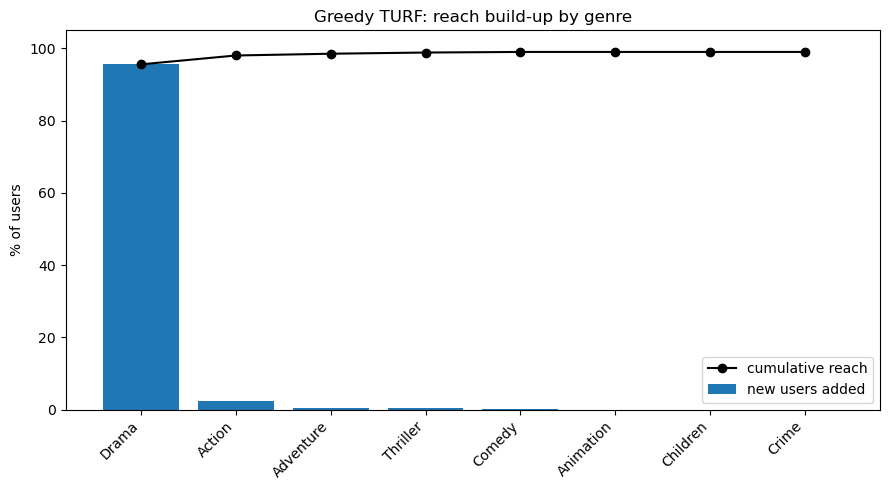

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(greedy["added"], greedy["incremental_reach"] * 100, label="new users added")
ax.plot(greedy["added"], greedy["cumulative_reach"] * 100, marker="o", color="black", label="cumulative reach")
ax.set_ylabel("% of users"); ax.set_ylim(0, 105)
ax.set_title("Greedy TURF: reach build-up by genre")
plt.xticks(rotation=45, ha="right"); ax.legend(); plt.tight_layout(); plt.show()

In [27]:
# writing again with 4 steps instead of 8 steps for output
def greedy_turf(M, labels, steps):
    chosen, covered, rows = [], np.zeros(M.shape[0], dtype=bool), []
    n = M.shape[0]
    for _ in range(steps):
        gains = [(-1 if j in chosen else (~covered & M[:, j]).sum()) for j in range(M.shape[1])]
        j = int(np.argmax(gains))
        chosen.append(j)
        covered |= M[:, j]
        rows.append({"step": len(chosen), "added": labels[j],
                     "incremental_reach": gains[j] / n, "cumulative_reach": covered.mean(), 
                     "new_users_reached": int(gains[j])})
    return pd.DataFrame(rows)

greedy = greedy_turf(M, genres, steps=4)
display(greedy.style.format({"incremental_reach": "{:.1%}", "cumulative_reach": "{:.1%}"}))

,step,added,incremental_reach,cumulative_reach,new_users_reached
0,1,Drama,95.6%,95.6%,583
1,2,Action,2.5%,98.0%,15
2,3,Adventure,0.5%,98.5%,3
3,4,Thriller,0.3%,98.9%,2


# Results of Maximized Turf Analysis

Maximized Turf: 4 genres: Drama + Action + Adventure + Thriller | Reach: 98.9% 

Initial Turf: 4 genres: Action + Comedy + Drama + Thriller | Reach: 99.0164% | Avg frequency: 3.675

Inital / Exhaustive Turf asks "What is the best combination?", and the Maximized Turf asks "If I add one genere at a time, which should I add next to gain the most users?". 

What we go foward with as a solution is actually based on business context. Here is a decision framework I'd use to set the stage for the conversation:

| Decision factor | Exhaustive TURF | Maximized TURF |
|---|---|---|
| Primary purpose | Find the best possible bundle | Build a bundle incrementally |
| What it optimizes | Total unique reach across all combinations | New reach added at each step |
| Optimality | Guarantees the global optimum for a fixed bundle size | No guarantee of global optimum |
| Best use in your project | Final genre recommendation | Explain the value of adding each genre |
| Main trade-off | More computation as options increase | Faster, but may miss the best combination |

### Conclusion
Both TURF approaches identified four-genre bundles that reach approximately 99% of users. The exhaustive search (Initial TURF) selected Action, Comedy, Drama, and Thriller, achieving 99.02% reach with an average frequency of 3.68 genres per reached user. The greedy approach (Maximized TURF) selected Drama, Action, Adventure, and Thriller, achieving 98.9% reach. Because the exhaustive bundle reaches slightly more users, it is the recommended four-genre combination if the objective is to maximize audience reach. The difference is small, however, so the greedy bundle may also be a viable option if Adventure is strategically important.

## Top Movies

In [20]:
TOP_N = 50   # candidate pool: the N most-rated movies

top_movies = ratings["movieId"].value_counts().head(TOP_N).index
liked_top = likes[likes["movieId"].isin(top_movies)]

movie_matrix = (
    pd.crosstab(liked_top["userId"], liked_top["movieId"])
      .reindex(index=all_users, columns=top_movies, fill_value=0) > 0
)
titles = movies.set_index("movieId").loc[top_movies, "title"].to_numpy()

movie_greedy = greedy_turf(movie_matrix.to_numpy(), titles, steps=10)
display(movie_greedy.style.format({"incremental_reach": "{:.1%}", "cumulative_reach": "{:.1%}"}))

,step,added,incremental_reach,cumulative_reach
0,1,"Shawshank Redemption, The (1994)",44.9%,44.9%
1,2,Star Wars: Episode IV - A New Hope (1977),16.4%,61.3%
2,3,Forrest Gump (1994),8.7%,70.0%
3,4,Pulp Fiction (1994),6.1%,76.1%
4,5,"Matrix, The (1999)",3.1%,79.2%
5,6,Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lost Ark) (1981),2.5%,81.6%
6,7,Toy Story (1995),2.0%,83.6%
7,8,American Beauty (1999),1.5%,85.1%
8,9,"Dark Knight, The (2008)",1.3%,86.4%
9,10,Fargo (1996),1.0%,87.4%


## Sensitivity Analysis to determine which Parameters are best

TURF analysis depends on two assumptions:
* Rating threshold: What rating counts as a positive preference? I will test 3.5, 4.0, and 4.5 stars.
* Minimum number of qualifying movies: How many movies must a user rate at or above that threshold in a genre before you count that genre as a preference? I will test 1 - 5 movies.

Sensitivity Analysis helps us answer three important questions:
1. Is the recommendation robust? Does the same genre bundle keep appearing under different assumptions?
2. How much does reach depend on the definition of a preference? If reach changes sharply, our headline result needs that qualification.
3. What trade-off are we willing to make? A stricter preference definition may give us a more conservative estimate of audience reach, but it may also make our target audience much smaller.

In [ ]:
SENSITIVITY_THRESHOLDS = [3.5, 4.0, 4.5]
SENSITIVITY_MIN_LIKES = [1, 2, 3, 4, 5]
SENSITIVITY_BUNDLE_SIZE = 4
TARGET_REACH = 0.98

sensitivity_rows = []
for threshold in SENSITIVITY_THRESHOLDS:
    threshold_likes = ratings[ratings["rating"] >= threshold]
    threshold_counts = (
        threshold_likes.merge(movie_genres, on="movieId")
        .groupby(["userId", "genre"]).size()
        .unstack(fill_value=0)
        .reindex(index=all_users, columns=genres, fill_value=0)
    )

    for min_likes in SENSITIVITY_MIN_LIKES:
        sensitivity_matrix = (threshold_counts >= min_likes).to_numpy()
        for bundle_size in range(1, SENSITIVITY_BUNDLE_SIZE + 1):
            top_bundle = turf(sensitivity_matrix, genres, bundle_size).iloc[0]
            sensitivity_rows.append({
                "like_threshold": threshold,
                "min_likes": min_likes,
                "bundle_size": bundle_size,
                "bundle": top_bundle["bundle"],
                "reach": top_bundle["reach"],
                "avg_frequency": top_bundle["avg_frequency"],
            })

parameter_sensitivity = pd.DataFrame(sensitivity_rows)
reach_by_size = parameter_sensitivity.pivot(
    index=["like_threshold", "min_likes"],
    columns="bundle_size",
    values="reach",
).rename(columns=lambda size: f"reach_k{size}")

best_at_cap = (
    parameter_sensitivity[parameter_sensitivity["bundle_size"] == SENSITIVITY_BUNDLE_SIZE]
    .set_index(["like_threshold", "min_likes"])[["bundle", "avg_frequency"]]
    .rename(columns={
        "bundle": f"best_bundle_k{SENSITIVITY_BUNDLE_SIZE}",
        "avg_frequency": f"avg_frequency_k{SENSITIVITY_BUNDLE_SIZE}",
    })
)
sensitivity_summary = reach_by_size.join(best_at_cap).reset_index()
display(sensitivity_summary.sort_values(["like_threshold", "min_likes"]))

eligible_settings = sensitivity_summary[
    sensitivity_summary[f"reach_k{SENSITIVITY_BUNDLE_SIZE}"] >= TARGET_REACH
]
if not eligible_settings.empty:
    recommendation = eligible_settings.sort_values(
        ["like_threshold", "min_likes"], ascending=False
    ).iloc[0]
    recommendation_reason = (
        f"Strictest tested parameter pair meeting {TARGET_REACH:.0%} reach "
        f"with a {SENSITIVITY_BUNDLE_SIZE}-genre bundle."
    )
else:
    recommendation = sensitivity_summary.sort_values(
        [f"reach_k{SENSITIVITY_BUNDLE_SIZE}", "like_threshold", "min_likes"],
        ascending=[False, False, False],
    ).iloc[0]
    recommendation_reason = (
        f"No tested pair met {TARGET_REACH:.0%} reach; selected the pair with "
        f"the highest reach at {SENSITIVITY_BUNDLE_SIZE} genres."
    )

print(recommendation_reason)
print(
    f"LIKE_THRESHOLD={recommendation['like_threshold']:.1f}, "
    f"MIN_LIKES={int(recommendation['min_likes'])}, "
    f"reach={recommendation[f'reach_k{SENSITIVITY_BUNDLE_SIZE}']:.1%}, "
    f"bundle={recommendation[f'best_bundle_k{SENSITIVITY_BUNDLE_SIZE}']}"
)

,like_threshold,min_likes,reach_k1,reach_k2,reach_k3,reach_k4,best_bundle_k4,avg_frequency_k4
0,3.5,1,0.993443,0.998361,0.998361,0.998361,Action + Comedy + Drama + Thriller,3.947455
1,3.5,2,0.981967,0.993443,0.995082,0.996721,Comedy + Documentary + Drama + Thriller,3.093750
2,3.5,3,0.967213,0.986885,0.991803,0.991803,Action + Comedy + Drama + Thriller,3.753719
3,3.5,5,0.916393,0.950820,0.965574,0.968852,Action + Comedy + Drama + Thriller,3.494078
4,4.0,1,0.993443,0.998361,0.998361,0.998361,Action + Comedy + Drama + Thriller,3.929392
5,4.0,2,0.977049,0.993443,0.995082,0.996721,Action + Comedy + Documentary + Drama,3.037829
6,4.0,3,0.955738,0.980328,0.986885,0.990164,Action + Comedy + Drama + Thriller,3.675497
7,4.0,5,0.898361,0.939344,0.952459,0.955738,Action + Comedy + Drama + Thriller,3.420240
8,4.5,1,0.954098,0.977049,0.980328,0.980328,Action + Comedy + Drama + Thriller,3.680602
9,4.5,2,0.895082,0.929508,0.944262,0.947541,Action + Comedy + Drama + Thriller,3.385813


Strictest tested parameter pair meeting 98% reach with a 4-genre bundle.
LIKE_THRESHOLD=4.5, MIN_LIKES=1, reach=98.0%, bundle=Action + Comedy + Drama + Thriller


## Results of Sensitivity Analysis
The sensitivity analysis shows that estimated audience reach depends on how genre preference is defined. Across the 12 tested combinations of rating threshold (3.5–4.5 stars) and minimum qualifying movies (1–5), the optimal four-genre bundle consistently included Action, Drama, and Thriller in 11 of 12 settings, while Comedy was replaced by Documentary in one setting. Action + Comedy + Drama + Thriller was the optimal bundle in 11 of 12 settings, with reach ranging from 79.67% to 99.84%. As preference criteria became more restrictive, reach generally declined, falling to 79.67% when users needed at least five movies rated 4.5 stars or higher in a genre. 

Overall, the recurring selection of Action, Comedy, Drama, and Thriller supports this bundle as a robust recommendation across the tested assumptions, although the estimated audience size varies substantially with the preference definition.

Based on my sensitivity analysis, the settings that produced the reported 99.0164% reach were:
* Rating threshold: 4.0 stars
* Minimum qualifying movies: 3 per genre
* Optimal four-genre bundle: Action + Comedy + Drama + Thriller
* Reach: 99.0164%
* Average frequency: 3.675 genres per reached user

# Overall Conclusion

Exhaustive TURF analysis identified Action, Comedy, Drama, and Thriller as the optimal four-genre bundle, reaching 99.02% of users under the primary preference definition, with an average frequency of 3.68 selected genres per reached user. The maximized TURF approach identified a similar bundle, replacing Comedy with Adventure, and achieved 98.9% reach. Given the marginal difference in reach, the exhaustive bundle is the recommended choice when maximizing audience coverage is the primary objective.

Sensitivity analysis further supports this recommendation: Action, Comedy, Drama, and Thriller emerged as the optimal bundle in 11 of 12 tested combinations of rating thresholds and minimum qualifying movies. However, estimated reach varied from 79.67% to 99.84%, demonstrating that audience coverage is sensitive to how genre preference is defined. The findings therefore support the consistency of the recommended genre combination more strongly than any single reach estimate.

Overall, Action, Comedy, Drama, and Thriller offer the strongest data-driven starting point for a four-genre content or promotional strategy. The estimated reach should be interpreted in the context of the chosen preference criteria, since MovieLens ratings indicate observed rating-based preferences rather than confirmed intent to watch.

# Product Recommendations

Prioritize Action, Comedy, Drama, and Thriller as the initial four-genre portfolio. Exhaustive TURF analysis estimated 99.02% audience reach under the primary preference definition, and sensitivity analysis selected this same bundle in 11 of 12 tested scenarios. This consistency makes it a strong starting point for maximizing potential audience coverage.

Next, translate the finding into a testable product strategy:

* Validate with behavioral data: Test whether users who show rating-based preferences for these genres actually engage with recommendations or content featuring them.

* Run a recommendation experiment: Compare a four-genre strategy against the current recommendation experience, measuring engagement metrics such as click-through rate, watch starts, completion rate, and retention. 

* Segment the results: Assess whether the optimal genre mix differs across user cohorts, such as highly engaged versus casual users.

* Optimize beyond reach: If the goal is sustained engagement rather than maximum coverage alone, evaluate whether genre combinations that increase viewing depth, satisfaction, or retention outperform the highest-reach bundle.

The analysis identifies a promising genre combination, not proof of improved product performance. A controlled experiment would establish whether using this combination produces meaningful improvements in user behavior!